# Model Build

This notebook builds several models using cross validation and selects the one with the best average r-squared value
Notable steps:
- read in multi-stint dataset
- add features on a per-stint basis to avoid bleed, including lagging and rate features.
- Keep one stint out for final testing; use remaining stints for training and validation
- Identify top features per pre-selected groups using SHAP on XGBRegressor
- Use "Leave One Stint Out" Cross Validation to train 5 separate models and report on mean r-squared, RMSE values
- Build final model and report


## Load Data and add features

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import time

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
import shap
import matplotlib.pyplot as plt


from assign_turns_to_df import assign_turns_to_dataframe
from degradation_components_full import (
    compute_friction_penalty,
    compute_thermal_aging_penalty,
    compute_asymmetric_penalty,
    compute_transient_penalty,
    compute_corner_g_loss_by_turn,
    compute_combined_degradation,
    estimate_per_tire_fx,
    estimate_slip_power
)


In [2]:
# 1. Load your data
df = pd.read_parquet("parquet_files\\master_12hz_8stints.parquet")

# drop warmup lap and stop at lap 15
laps_to_plot = np.arange(1,16)

df = df[(df["Lap"].isin(laps_to_plot))]

df["LatG"] = df["LatAccel"].abs()
df["LongG"] = df["LongAccel"].abs()

df['source_file'].unique()

array(['porsche992cup_lagunaseca 2025-06-18 11-58-07_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-17 21-37-16_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-17 10-52-45_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-16 21-04-27_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-12 13-27-52_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-10 21-09-23_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-04 13-19-02_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-11 14-37-57_Stint_1.csv'],
      dtype=object)

In [3]:
# --- 2. Engineer Rate-of-Change Features ---
# ~250ms smoothing at 12Hz
def compute_input_roc(df, cols, sampling_rate_hz=12):
    for col in cols:
        smoothed = df[col].rolling(3, min_periods=1).mean()
        df[f"{col}_rate"] = smoothed.diff() * sampling_rate_hz
    return df


# lag features
hz = 12
window = 3 * hz  # 3 seconds
step = hz // 4

# base features gathered from EDA???
base_features = [
    "Throttle", "Brake", "SteeringWheelAngle",
    "LatAccel", "LongAccel", "Speed",
    "LFtempM", "RFtempM", "LRtempM", "RRtempM",
    "LFshockDefl", "RFshockDefl", "LRshockDefl", "RRshockDefl",
    "LFpressure", "RFpressure", "LRpressure", "RRpressure",
    "LatG", "VertAccel", "PitchRate"
    , "LFspeed", "RFspeed", "LRspeed", "RRspeed"
]

# Initialize empty list to collect updated chunks
updated_chunks = []

for stint_id, stint_df in df.groupby("source_file", sort=False):
    #print(stint_id)
    stint_df = stint_df.copy()

    stint_df = assign_turns_to_dataframe(stint_df, "turn_ranges_laguna_seca.csv")
    stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN
    stint_df["corner_g_loss"] = compute_corner_g_loss_by_turn(stint_df)
    stint_df = estimate_per_tire_fx(stint_df)
    stint_df["slip_power"] = estimate_slip_power(stint_df)

    # Generate lagged features efficiently
    lagged_cols = []
    for feature in base_features:
        for lag in range(0, window + 1, step):
            col_name = f"{feature}_lag_{lag}"
            lagged_cols.append(stint_df[feature].shift(lag).rename(col_name))

    # Concatenate all lagged columns at once
    lagged_df = pd.concat(lagged_cols, axis=1)

    # Combine with original df (use .copy() to defragment memory)
    stint_df = pd.concat([stint_df.copy(), lagged_df], axis=1)


    input_signals = ['Throttle', 'Brake', 'SteeringWheelAngle']  # Extend as needed
    stint_df = compute_input_roc(stint_df, input_signals)

    # Recompute each degradation component
    stint_df["friction_penalty"] = compute_friction_penalty(stint_df)
    stint_df["transient_penalty"] = compute_transient_penalty(stint_df)
    stint_df["asym_penalty"] = compute_asymmetric_penalty(stint_df)
    stint_df["vulcan_penalty"] = compute_thermal_aging_penalty(stint_df)
    stint_df = compute_combined_degradation(stint_df)

    # Clip the degradation deltas
    lower = stint_df['deg_delta_3s'].quantile(0.01)
    upper = stint_df['deg_delta_3s'].quantile(0.99)
    stint_df['deg_delta_3s'] = stint_df['deg_delta_3s'].clip(lower, upper)

    stint_df = stint_df.dropna(subset=["deg_delta_3s"]).reset_index(drop=True) # drop NaN scores - should be at beginning and end

    updated_chunks.append(stint_df)

# Concatenate all updated stints back into a single DataFrame
df = pd.concat(updated_chunks, ignore_index=True)

#df["combined_degradation"] = df.groupby("stint_id")["combined_degradation"].transform(lambda x: x - x.min())
    
df.shape
df.head()

C:\Users\cisan\AppData\Local\Temp\ipykernel_98992\434092814.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN
C:\Users\cisan\AppData\Local\Temp\ipykernel_98992\434092814.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN
C:\Users\cisan\AppData\Local\Temp\ipykernel_98992\434092814.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call resul

,AirDensity,AirPressure,AirTemp,Alt,Brake,BrakeABSactive,BrakeABScutPct,BrakeRaw,CFSRrideHeight,Clutch,...,RRspeed_lag_36,Throttle_rate,Brake_rate,SteeringWheelAngle_rate,friction_penalty,transient_penalty,asym_penalty,vulcan_penalty,combined_degradation,deg_delta_3s
0,1.16734,98740.8,19.8105,235.535,0.0,0,100.0,0.0,0.075976,100.0,...,53.2400,0.0,0.0,0.089120,0.049021,0.0,0.151168,0.0,0.050047,-0.028738
1,1.16734,98740.8,19.8105,235.435,0.0,0,100.0,0.0,0.070087,100.0,...,53.4946,0.0,0.0,0.070500,0.036817,0.0,0.160844,0.0,0.049415,-0.042527
2,1.16734,98740.8,19.8105,235.335,0.0,0,100.0,0.0,0.076231,100.0,...,53.6376,0.0,0.0,0.016648,0.036645,0.0,0.227334,0.0,0.065995,-0.053411
3,1.16734,98740.8,19.8105,235.235,0.0,0,100.0,0.0,0.065057,100.0,...,53.8211,0.0,0.0,0.109668,0.042265,0.0,0.208607,0.0,0.062718,-0.038889
4,1.16734,98740.8,19.8105,235.135,0.0,0,100.0,0.0,0.062643,100.0,...,54.0537,0.0,0.0,-0.051892,0.026689,0.0,0.273171,0.0,0.074965,-0.037508


In [4]:
# 1a. Manually drop known redundant columns
drop_manual = ['RFtempCL', 'RFtempCR', 'LFtempCL', 'LFtempCR', 'LRtempCL', 'LRtempCR', 'RRtempCL', 'RRtempCR']
df = df.drop(columns=[col for col in drop_manual if col in df.columns])

In [5]:
# Define features and target
target = "deg_delta_3s"
feature_cols = [col for col in df.columns if col not in [target, 'source_file','friction_penalty', 'vulcan_penalty',
    'asym_penalty', 'transient_penalty', 'combined_degradation','deg_delta_3s','deg_delta_3s_clipped']]
print(feature_cols)

['AirDensity', 'AirPressure', 'AirTemp', 'Alt', 'Brake', 'BrakeABSactive', 'BrakeABScutPct', 'BrakeRaw', 'CFSRrideHeight', 'Clutch', 'ClutchRaw', 'dpLFTireChange', 'dpLFTireColdPress', 'dpLRTireChange', 'dpLRTireColdPress', 'dpRFTireChange', 'dpRFTireColdPress', 'dpRRTireColdPress', 'Engine0_RPM', 'Gear', 'IsOnTrack', 'IsOnTrackCar', 'LatAccel', 'LFbrakeLinePress', 'LFcoldPressure', 'LFpressure', 'LFrideHeight', 'LFshockDefl', 'LFshockVel', 'LFtempCM', 'LFtempL', 'LFtempM', 'LFtempR', 'LFwearL', 'LFwearM', 'LFwearR', 'LongAccel', 'LRbrakeLinePress', 'LRcoldPressure', 'LRpressure', 'LRrideHeight', 'LRshockDefl', 'LRshockVel', 'LRtempCM', 'LRtempL', 'LRtempM', 'LRtempR', 'LRwearL', 'LRwearM', 'LRwearR', 'OilTemp', 'Pitch', 'PitchRate', 'RelativeHumidity', 'RFbrakeLinePress', 'RFcoldPressure', 'RFpressure', 'RFrideHeight', 'RFshockDefl', 'RFshockVel', 'RFtempCM', 'RFtempL', 'RFtempM', 'RFtempR', 'RFwearL', 'RFwearM', 'RFwearR', 'Roll', 'RollRate', 'RPM', 'RRbrakeLinePress', 'RRcoldPressur

In [6]:
#model_df = df[feature_cols].dropna()

# 6. Train/test split
stint_list = df["source_file"].unique().tolist()
test_stint_num = 4

test_stint_list = [stint_list[test_stint_num]]
train_stint_list = [item for item in stint_list if item not in test_stint_list]

train_val_df = df[df["source_file"].isin(train_stint_list)].copy()
test_df = df[df["source_file"].isin(test_stint_list)].copy()

target_col = "deg_delta_3s"
X_train_val = train_val_df[feature_cols].astype(float)

y_train_val = train_val_df[target_col]

X_test = test_df[X_train_val.columns]
y_test = test_df[target_col]

In [7]:
# --- 5. SHAP Analysis ---
xgb_model = XGBRegressor(tree_method='hist', device='cuda', n_estimators=100, random_state=42)
xgb_model.fit(X_train_val.values, y_train_val.values)

explainer = shap.Explainer(xgb_model, X_train_val)
shap_values = explainer(X_train_val)

100%|===================| 111518/111746 [03:19<00:00]        

In [8]:
# --- 6. Group Features and Select Top-N per Group ---
def top_shap_features_by_category(shap_values, X, groups, top_n=5):
    mean_shap = np.abs(shap_values.values).mean(axis=0)
    shap_df = pd.DataFrame({'feature': X.columns, 'importance': mean_shap})
    
    grouped_top_feats = {}
    for label, cols in groups.items():
        subset = shap_df[shap_df['feature'].isin(cols)]
        top_feats = subset.sort_values('importance', ascending=False).head(top_n)['feature'].tolist()
        grouped_top_feats[label] = top_feats
    return grouped_top_feats

In [9]:
# Define categories manually
driver_input_list = ['Throttle', 'Brake', 'SteeringWheelAngle']
car_dynamics_list = ['LatG','LongG','Pitch','PitchRate', 'Roll', 'RollRate', 'Yaw','YawRate','Speed','LatAccel','LongAccel','VertAccel','LFshockDefl','RFshockDefl','LRshockDefl','RRshockDefl']
tire_signals_list = ["LFtempM", "RFtempM", "LRtempM", "RRtempM","LFpressure", "RFpressure", "LRpressure", "RRpressure", "LFspeed", "RFspeed", "LRspeed", "RRspeed"]
feature_groups = {
    #"Driver Inputs": [c for c in X_train_val.columns if any(x in c for x in ['Throttle', 'Brake', 'SteeringWheelAngle']) and '_rate' not in c and '_lag' not in c],
    "Driver Inputs": driver_input_list
    #,"Input Rates": [c for c in X_train_val.columns if any(x in c for x in ['Throttle', 'Brake', 'SteeringWheelAngle']) and'_rate' in c and '_lag' not in c],
    ,"Input Rates": [c for c in X_train_val.columns if any(x in c for x in driver_input_list) and '_rate' in c and '_lag_' not in c]
    ,"Input Lags": [c for c in X_train_val.columns if any(x in c for x in driver_input_list) and '_rate' not in c and '_lag_' in c]
    ,"Car Dynamics": [c for c in X_train_val.columns if c in car_dynamics_list]
    ,"Dynamics Lags": [c for c in X_train_val.columns if any(x in c for x in car_dynamics_list) and '_rate' not in c and '_lag_' in c]
    ,"Tire Signals": [c for c in X_train_val.columns if c in tire_signals_list] #'temp' in c or 'pressure' in c]
    ,"Signals Lags": [c for c in X_train_val.columns if any(x in c for x in tire_signals_list) and '_rate' not in c and '_lag' in c]
    ,"Track Context": [c for c in X_train_val.columns if c in ['Alt', 'Slope', 'Turn']] #slope not in yet
}

#feature_groups

top_per_group = top_shap_features_by_category(shap_values, X_train_val, feature_groups, top_n=5)


In [10]:
# Flatten selected features
top_features = list(set([f for group in top_per_group.values() for f in group]))
print("Selected Features:", top_features)
print(len(top_features))

Selected Features: ['LRtempM_lag_21', 'RFspeed_lag_36', 'Pitch', 'Throttle_rate', 'SteeringWheelAngle_rate', 'Throttle_lag_24', 'Throttle', 'RRpressure_lag_3', 'SteeringWheelAngle', 'LatG', 'Turn', 'Brake_lag_33', 'SteeringWheelAngle_lag_6', 'LongAccel_lag_36', 'LFpressure', 'Brake_lag_36', 'Speed_lag_36', 'RFshockDefl_lag_0', 'LongAccel_lag_24', 'Brake', 'LRpressure', 'LongG', 'Alt', 'Brake_rate', 'Yaw', 'RFpressure', 'Throttle_lag_36', 'LRpressure_lag_24', 'LRspeed', 'LFpressure_lag_9', 'Roll', 'LatG_lag_15', 'RFspeed']
33


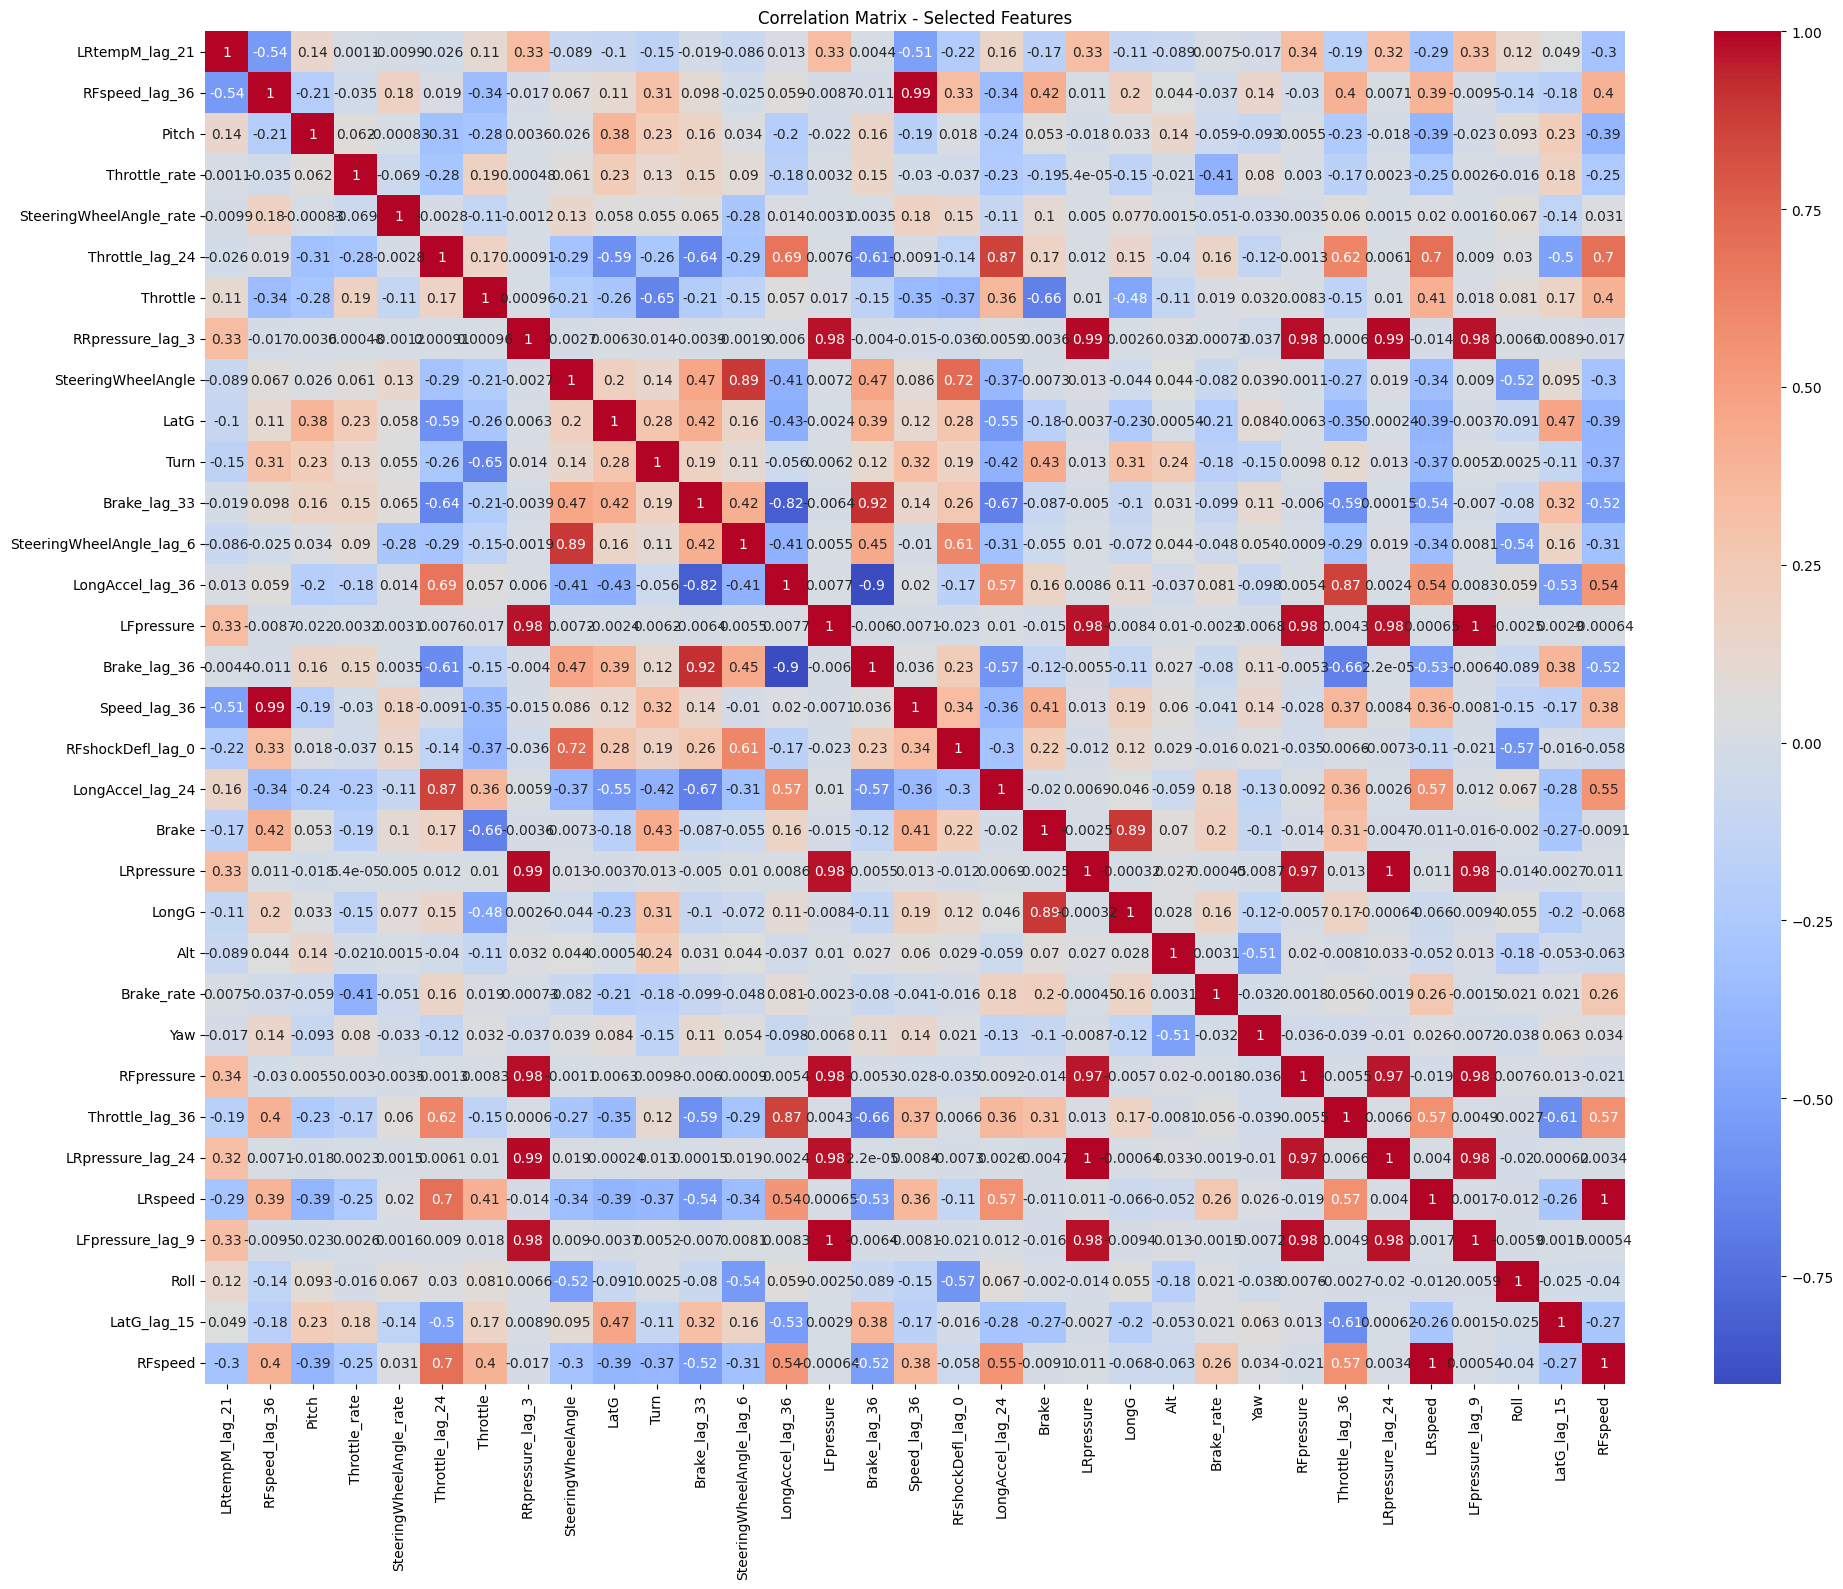

In [11]:
# Correlation heatmap for selected features
plt.figure(figsize=(20, 16))
sns.heatmap(X_train_val[top_features].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix - Selected Features")
plt.tight_layout()
plt.show()

In [12]:
# --- 2. Define Models ---
models = {
    "XGBoost": XGBRegressor(tree_method='hist', device='cuda', n_estimators=50, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=50, random_state=42),
    "Ridge": Ridge(alpha=1.0),
    "SVR": SVR(),
    "KNN": KNeighborsRegressor(n_neighbors=10)
}

In [14]:
# --- 3. LOSOCV Evaluation ---
groups = train_val_df["source_file"]
loso_results = []

X_train_val = X_train_val[top_features]
X_test = X_test[top_features]

#X = train_val_df[top_features].astype(float)
#y = train_val_df["deg_delta_3s"]

for model_name, model in models.items():
    gkf = GroupKFold(n_splits=groups.nunique())
    fold_r2, fold_rmse, fold_mae, fold_mape, fold_times = [], [], [], [], []

    for train_idx, val_idx in gkf.split(X_train_val, y_train_val, groups=groups):
        X_tr, X_val = X_train_val.iloc[train_idx], X_train_val.iloc[val_idx]
        y_tr, y_val = y_train_val.iloc[train_idx], y_train_val.iloc[val_idx]

        start = time.time()
        model.fit(X_tr.values, y_tr.values)
        end = time.time()
        preds = model.predict(X_val.values)
        fold_r2.append(r2_score(y_val, preds))
        fold_rmse.append(root_mean_squared_error(y_val, preds))
        fold_mae.append(mean_absolute_error(y_val, preds))
        fold_mape.append(mean_absolute_percentage_error(y_val, preds))
        fold_times.append(end - start)

    loso_results.append({
        "Model": model_name,
        "R2 (avg)": np.mean(fold_r2),
        "MAE (avg)": np.mean(fold_mae),
        "RMSE (avg)": np.mean(fold_rmse),
        "MAPE (avg)": np.mean(fold_mape),
        "Avg Train Time (s)": np.mean(fold_times)
    })

loso_df = pd.DataFrame(loso_results)
print("\nLOSOCV Results:")
print(loso_df)


LOSOCV Results:
          Model  R2 (avg)  MAE (avg)  RMSE (avg)  MAPE (avg)  \
0       XGBoost  0.880390   0.026104    0.038958    1.707740   
1  RandomForest  0.888686   0.023737    0.037551    1.546170   
2         Ridge  0.661400   0.050369    0.065637    4.063533   
3           SVR  0.676208   0.051540    0.064113    5.316319   
4           KNN  0.787344   0.035551    0.051801    2.324320   

   Avg Train Time (s)  
0            0.226275  
1          100.684926  
2            0.019141  
3          107.438211  
4            0.011234  


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error

# def root_mean_squared_error(y_true, y_pred):
#     return np.sqrt(mean_squared_error(y_true, y_pred))

def generate_losocv_plots(model_dict, X_train_val, y_train_val, groups, top_features):
    # Store predictions and ground truth per model
    model_names = []
    all_y_true = []
    all_y_pred = []

    for model_name, model in model_dict.items():
        gkf = GroupKFold(n_splits=groups.nunique())
        y_true_all, y_pred_all = [], []

        for train_idx, val_idx in gkf.split(X_train_val, y_train_val, groups=groups):
            X_tr = X_train_val.iloc[train_idx][top_features]
            X_val = X_train_val.iloc[val_idx][top_features]
            y_tr = y_train_val.iloc[train_idx]
            y_val = y_train_val.iloc[val_idx]

            model.fit(X_tr.values, y_tr.values)
            preds = model.predict(X_val.values)

            y_true_all.extend(y_val)
            y_pred_all.extend(preds)

        model_names.append(model_name)
        all_y_true.append(np.array(y_true_all))
        all_y_pred.append(np.array(y_pred_all))

    residuals_list = [y_true - y_pred for y_true, y_pred in zip(all_y_true, all_y_pred)]

    # Plot 1: True vs Predicted
    fig1, axes1 = plt.subplots(1, len(model_names), figsize=(25, 5))
    for i, ax in enumerate(axes1):
        ax.scatter(all_y_true[i], all_y_pred[i], alpha=0.5, s=10)
        ax.plot([min(all_y_true[i]), max(all_y_true[i])],
                [min(all_y_true[i]), max(all_y_true[i])],
                'r--', linewidth=1)
        ax.set_title(f"{model_names[i]}\nTrue vs Predicted")
        ax.set_xlabel("True")
        ax.set_ylabel("Predicted")
    fig1.tight_layout()
    plt.show()

    # Plot 2: Residuals vs True
    fig2, axes2 = plt.subplots(1, len(model_names), figsize=(25, 5))
    for i, ax in enumerate(axes2):
        ax.scatter(all_y_true[i], residuals_list[i], alpha=0.5, s=10)
        ax.axhline(0, color='r', linestyle='--', linewidth=1)
        ax.set_title(f"{model_names[i]}\nResiduals vs True")
        ax.set_xlabel("True")
        ax.set_ylabel("Residuals")
    fig2.tight_layout()
    plt.show()

    # Plot 3: Histogram of Residuals
    fig3, axes3 = plt.subplots(1, len(model_names), figsize=(25, 5))
    for i, ax in enumerate(axes3):
        sns.histplot(residuals_list[i], kde=True, bins=30, ax=ax)
        ax.axvline(0, color='r', linestyle='--', linewidth=1)
        ax.set_title(f"{model_names[i]}\nResidual Distribution")
        ax.set_xlabel("Residual")
        ax.set_ylabel("Frequency")
    fig3.tight_layout()
    plt.show()

    return all_y_true, all_y_pred, residuals_list


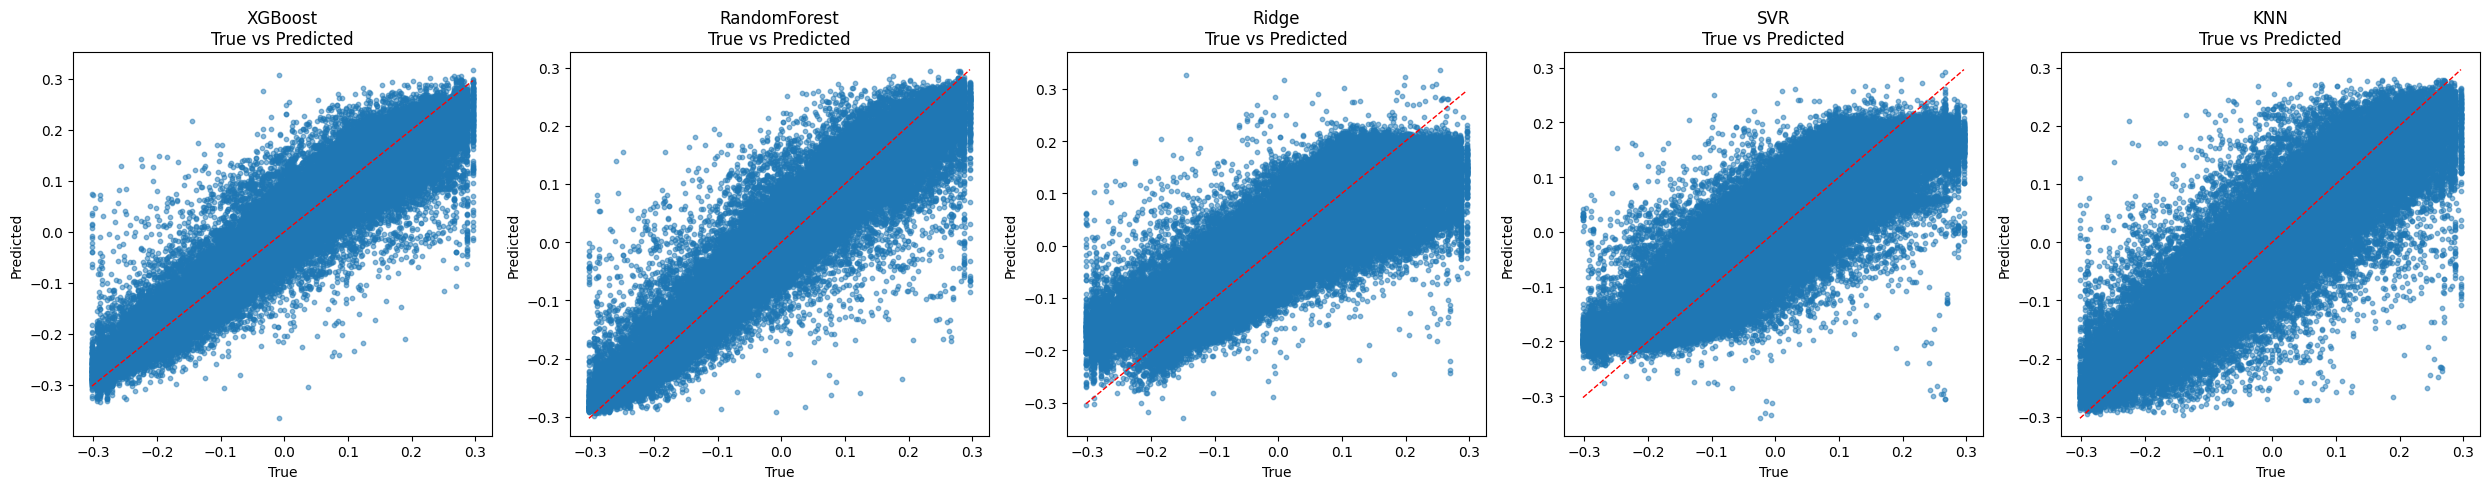

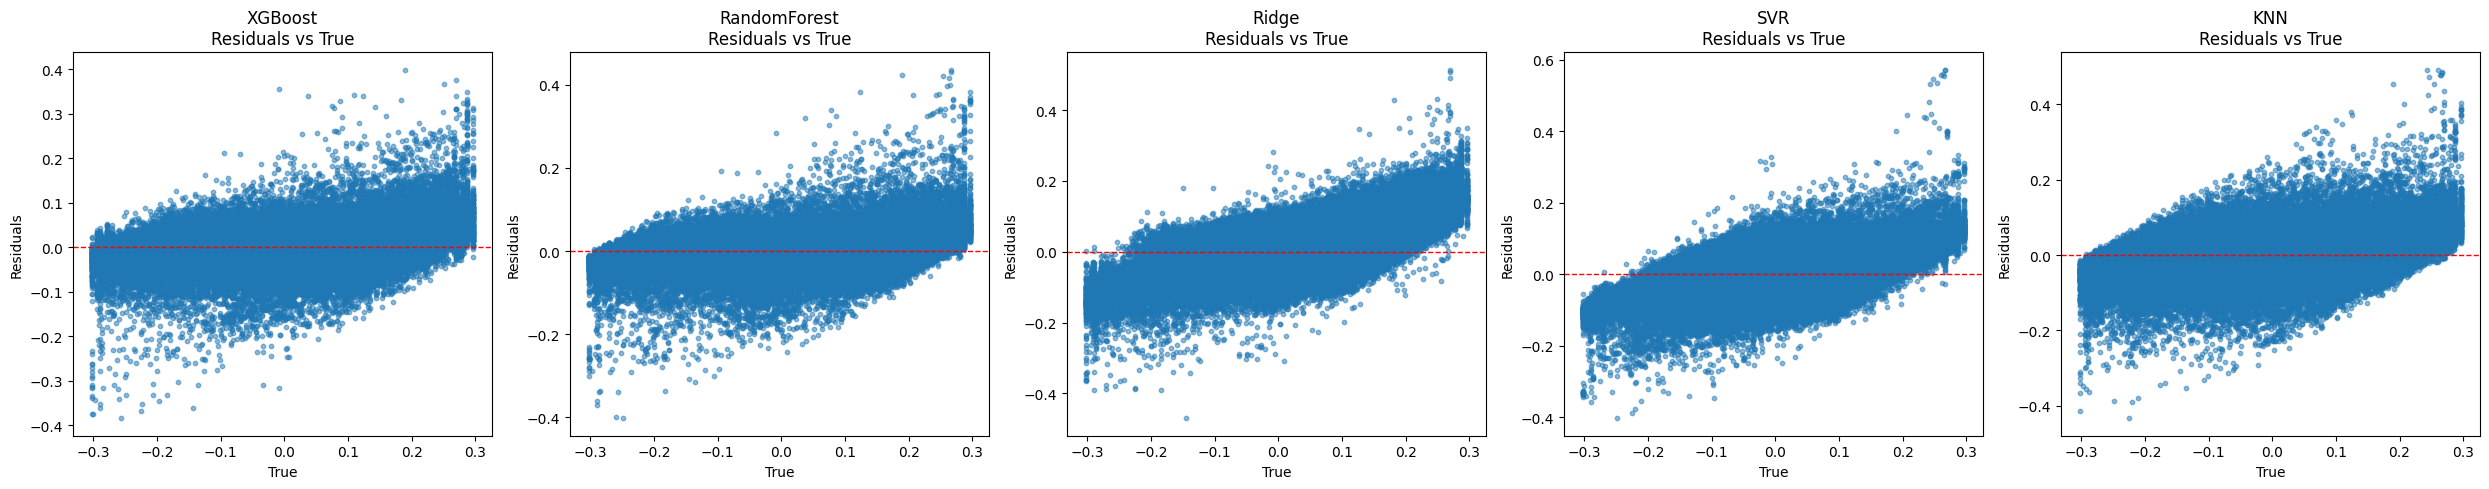

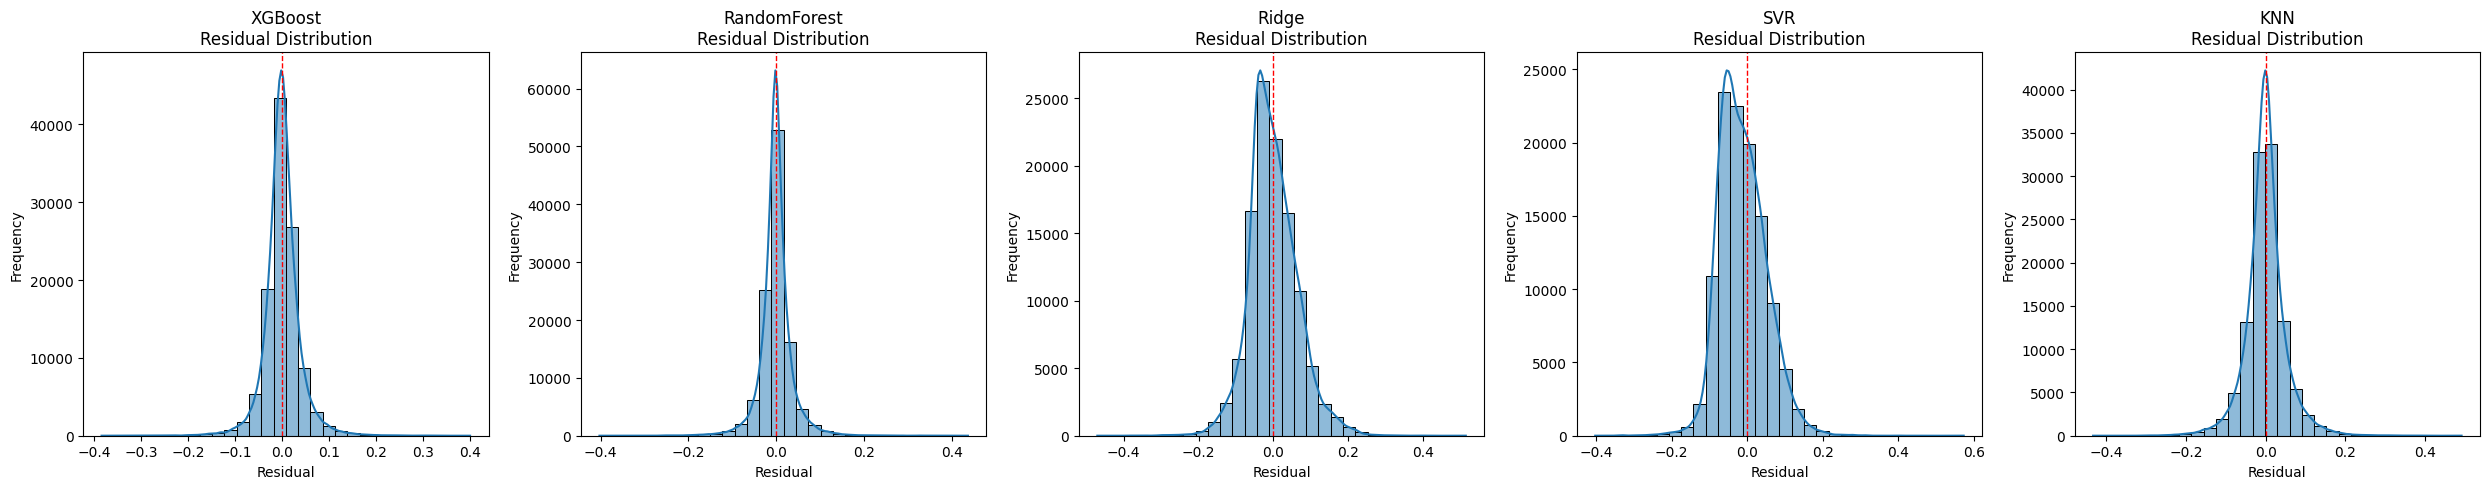

In [16]:
all_y_true, all_y_pred, residuals_list = generate_losocv_plots(
    models,
    X_train_val[top_features],
    y_train_val,
    train_val_df["source_file"],
    top_features
)

In [21]:
def generate_all_preds(model_dict, X_train_val, y_train_val, groups, top_features):
    # Store predictions and ground truth per model
    model_names = []
    all_y_true = []
    all_y_pred = []

    for model_name, model in model_dict.items():
        gkf = GroupKFold(n_splits=groups.nunique())
        y_true_all, y_pred_all = [], []

        for train_idx, val_idx in gkf.split(X_train_val, y_train_val, groups=groups):
            X_tr = X_train_val.iloc[train_idx][top_features]
            X_val = X_train_val.iloc[val_idx][top_features]
            y_tr = y_train_val.iloc[train_idx]
            y_val = y_train_val.iloc[val_idx]

            model.fit(X_tr.values, y_tr.values)
            preds = model.predict(X_val.values)

            y_true_all.extend(y_val)
            y_pred_all.extend(preds)

        model_names.append(model_name)
        all_y_true.append(np.array(y_true_all))
        all_y_pred.append(np.array(y_pred_all))

    residuals_list = [y_true - y_pred for y_true, y_pred in zip(all_y_true, all_y_pred)]

    return model_names, all_y_true, all_y_pred, residuals_list

model_names, all_y_true, all_y_pred, residuals_list = generate_all_preds(models,
    X_train_val[top_features],
    y_train_val,
    train_val_df["source_file"],
    top_features)


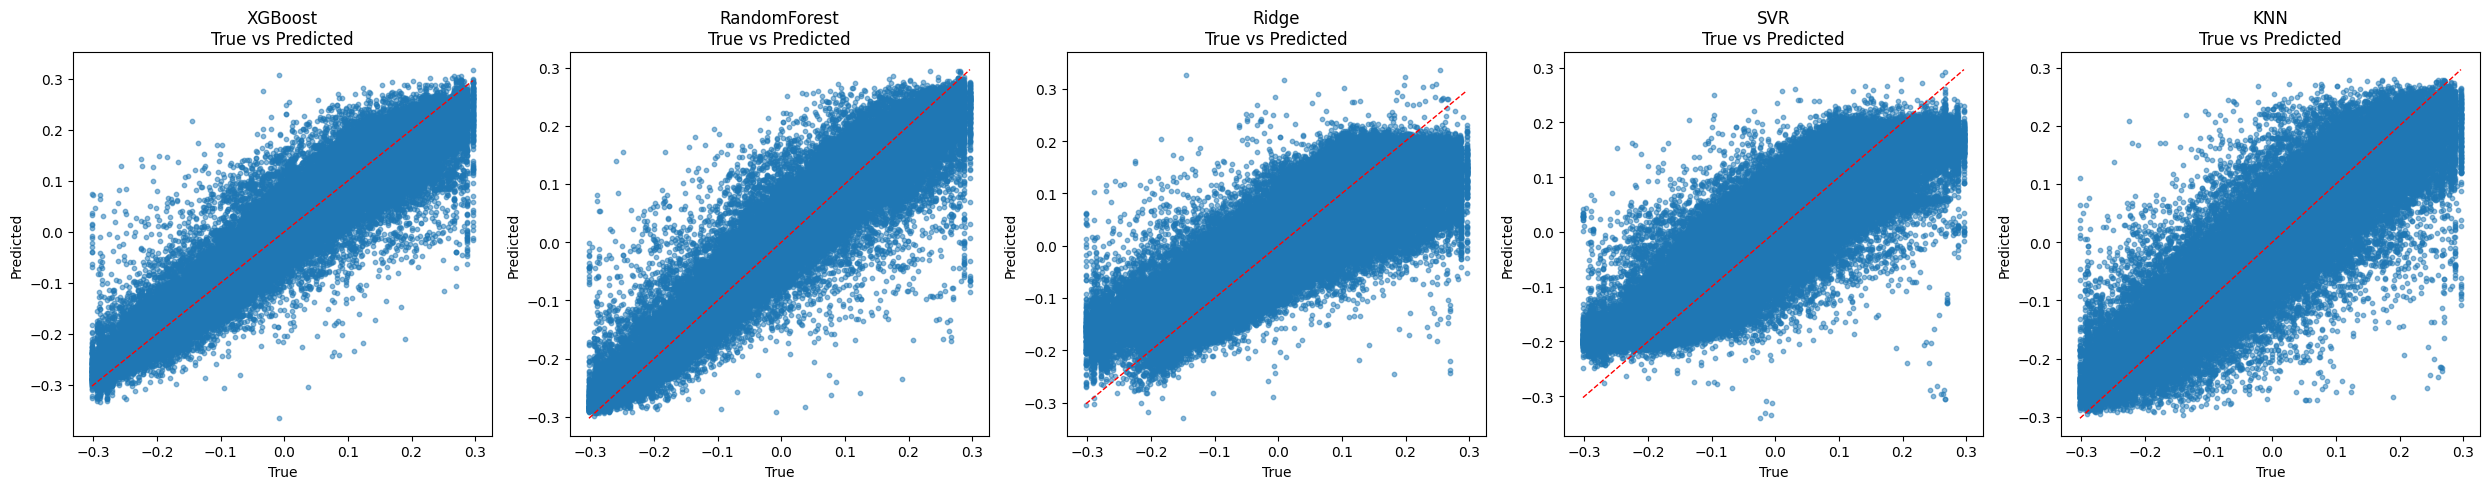

In [22]:
# Plot 1: True vs Predicted
fig1, axes1 = plt.subplots(1, len(model_names), figsize=(25, 5))
for i, ax in enumerate(axes1):
    ax.scatter(all_y_true[i], all_y_pred[i], alpha=0.5, s=10)
    ax.plot([min(all_y_true[i]), max(all_y_true[i])],
            [min(all_y_true[i]), max(all_y_true[i])],
            'r--', linewidth=1)
    ax.set_title(f"{model_names[i]}\nTrue vs Predicted")
    ax.set_xlabel("True")
    ax.set_ylabel("Predicted")
fig1.tight_layout()
plt.show()

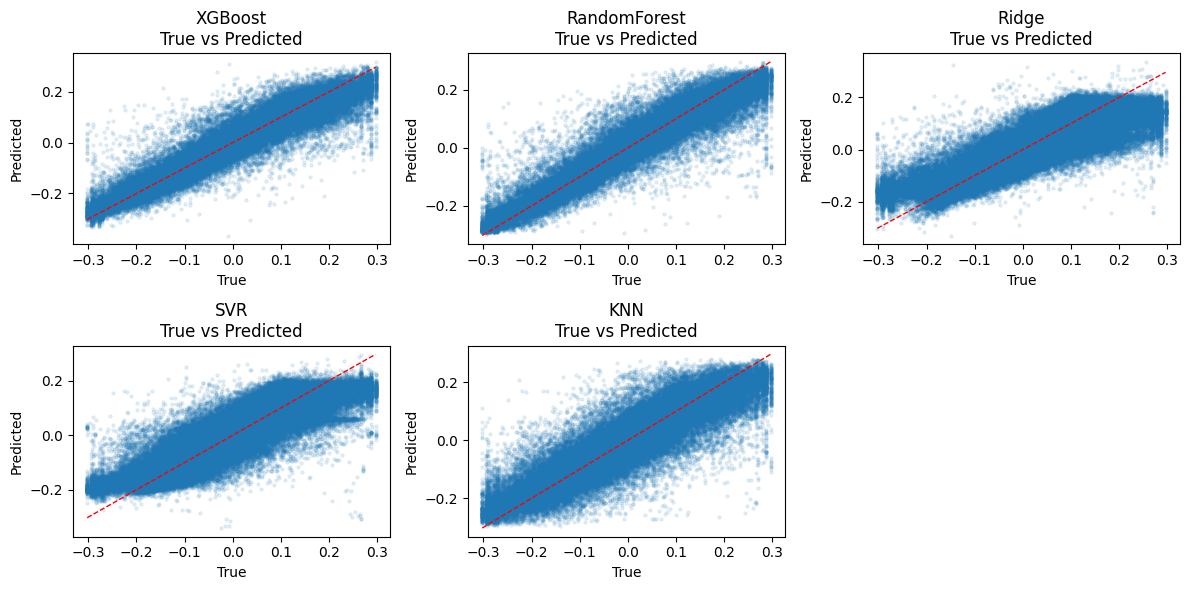

In [34]:
import matplotlib.pyplot as plt
import numpy as np

# --- Dummy Data for Demonstration ---
# In your actual script, all_y_true, all_y_pred, and model_names
# would already be defined. This is just to make the example runnable.
num_models = 5
#model_names = [f"Model {i+1}" for i in range(num_models)]
#all_y_true = [np.random.rand(50) * 100 for _ in range(num_models)]
#all_y_pred = [y_true + (np.random.rand(50) - 0.5) * 20 for y_true in all_y_true]
# --- End Dummy Data ---

# Create a figure and a 2x3 grid of subplots.
# We specify 2 rows and 3 columns.
# The figsize is adjusted to better fit the new layout.
fig1, axes = plt.subplots(2, 3, figsize=(12, 6))

# Flatten the axes array to easily iterate through all subplots.
# This converts the 2x3 array into a 1D array of 6 axes objects.
axes_flat = axes.flatten()

# Loop through your data and plot on the first 5 subplots.
# The last subplot (index 5 in a 0-indexed array) will remain empty.
for i in range(len(model_names)):
    ax = axes_flat[i] # Get the current subplot from the flattened array
    ax.scatter(all_y_true[i], all_y_pred[i], alpha=0.1, s=5)
    ax.plot([min(all_y_true[i]), max(all_y_true[i])],
            [min(all_y_true[i]), max(all_y_true[i])],
            'r--', linewidth=1)
    ax.set_title(f"{model_names[i]}\nTrue vs Predicted")
    ax.set_xlabel("True")
    ax.set_ylabel("Predicted")

# Hide the last (unused) subplot if there are fewer plots than available axes.
# In this case, we have 5 plots and 6 axes (2x3 grid), so the 6th one is empty.
if len(model_names) < len(axes_flat):
    for j in range(len(model_names), len(axes_flat)):
        fig1.delaxes(axes_flat[j]) # Remove the unused subplot

# Adjust layout to prevent titles/labels from overlapping.
fig1.tight_layout()

# Display the plot.
plt.show()


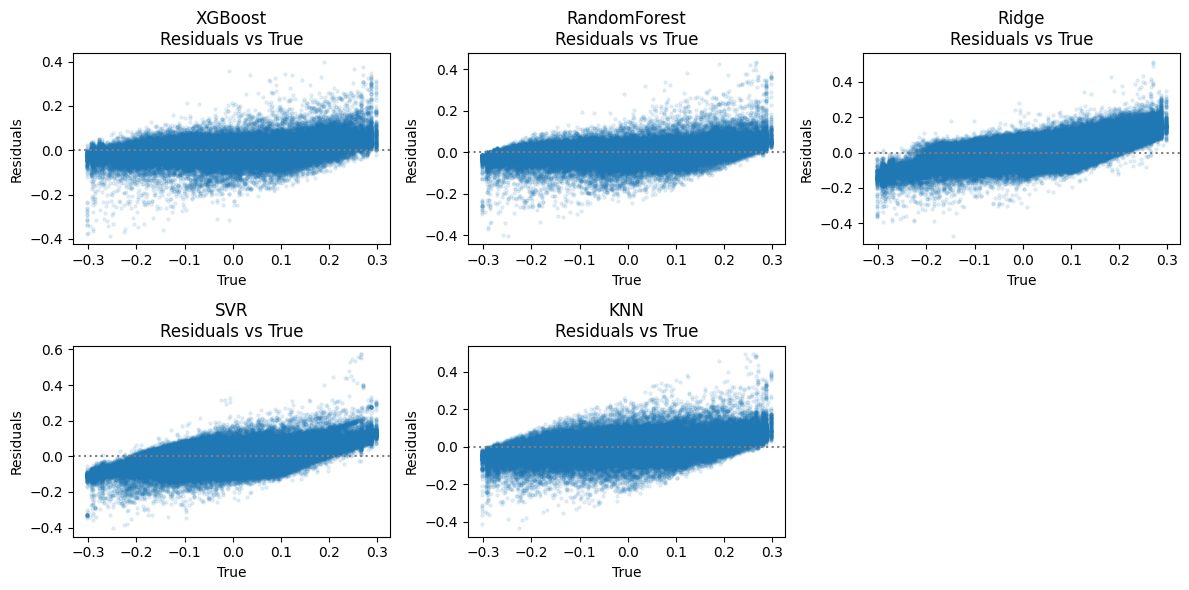

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- Dummy Data for Demonstration ---
# In your actual script, all_y_true, all_y_pred, and model_names
# would already be defined. This is just to make the example runnable.
num_models = 5
#model_names = [f"Model {i+1}" for i in range(num_models)]
#all_y_true = [np.random.rand(50) * 100 for _ in range(num_models)]
#all_y_pred = [y_true + (np.random.rand(50) - 0.5) * 20 for y_true in all_y_true]
# --- End Dummy Data ---

# Create a figure and a 2x3 grid of subplots.
# We specify 2 rows and 3 columns.
# The figsize is adjusted to better fit the new layout.
fig1, axes = plt.subplots(2, 3, figsize=(12, 6))

# Flatten the axes array to easily iterate through all subplots.
# This converts the 2x3 array into a 1D array of 6 axes objects.
axes_flat = axes.flatten()

# Loop through your data and plot on the first 5 subplots.
# The last subplot (index 5 in a 0-indexed array) will remain empty.
for i in range(len(model_names)):
    ax = axes_flat[i] # Get the current subplot from the flattened array
    ax.scatter(all_y_true[i], residuals_list[i], alpha=0.1, s=5)
    #ax.axhline(0, color='r', linestyle=':', linewidth=1)
    ax.axhline(0, linestyle=':', color='gray')
    ax.set_title(f"{model_names[i]}\nResiduals vs True")
    ax.set_xlabel("True")
    ax.set_ylabel("Residuals")

# Hide the last (unused) subplot if there are fewer plots than available axes.
# In this case, we have 5 plots and 6 axes (2x3 grid), so the 6th one is empty.
if len(model_names) < len(axes_flat):
    for j in range(len(model_names), len(axes_flat)):
        fig1.delaxes(axes_flat[j]) # Remove the unused subplot

# Adjust layout to prevent titles/labels from overlapping.
fig1.tight_layout()

# Display the plot.
plt.show()


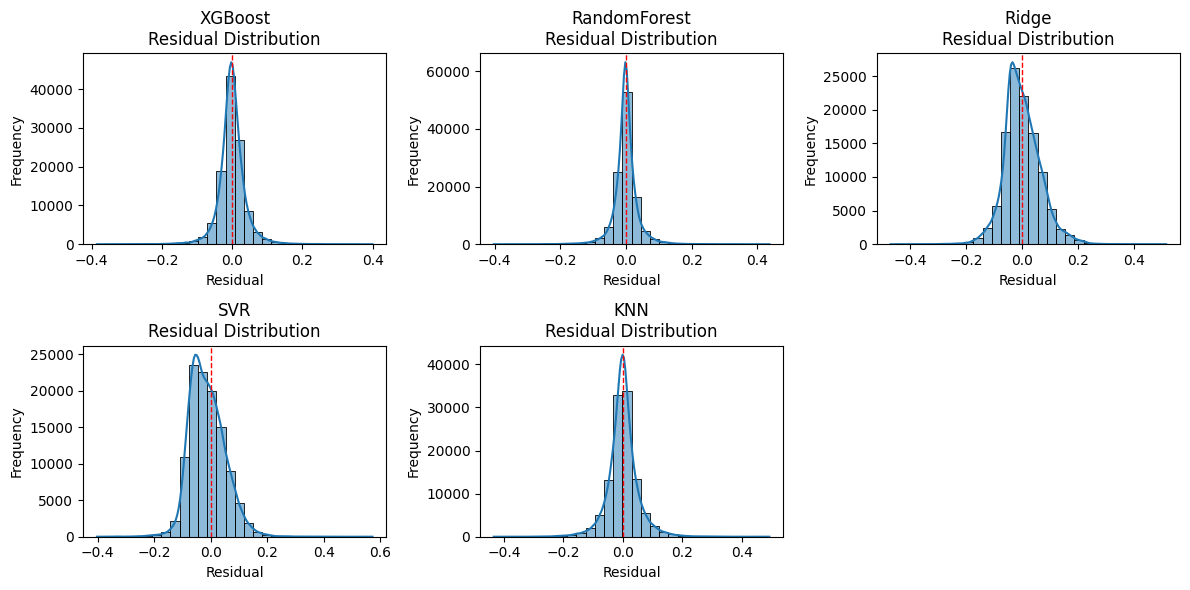

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# --- Dummy Data for Demonstration ---
# In your actual script, all_y_true, all_y_pred, and model_names
# would already be defined. This is just to make the example runnable.
num_models = 5
#model_names = [f"Model {i+1}" for i in range(num_models)]
#all_y_true = [np.random.rand(50) * 100 for _ in range(num_models)]
#all_y_pred = [y_true + (np.random.rand(50) - 0.5) * 20 for y_true in all_y_true]
# --- End Dummy Data ---

# Create a figure and a 2x3 grid of subplots.
# We specify 2 rows and 3 columns.
# The figsize is adjusted to better fit the new layout.
fig1, axes = plt.subplots(2, 3, figsize=(12, 6))

# Flatten the axes array to easily iterate through all subplots.
# This converts the 2x3 array into a 1D array of 6 axes objects.
axes_flat = axes.flatten()

# Loop through your data and plot on the first 5 subplots.
# The last subplot (index 5 in a 0-indexed array) will remain empty.
for i in range(len(model_names)):
    ax = axes_flat[i] # Get the current subplot from the flattened array
    sns.histplot(residuals_list[i], kde=True, bins=30, ax=ax)
    ax.axvline(0, color='r', linestyle='--', linewidth=1)
    ax.set_title(f"{model_names[i]}\nResidual Distribution")
    ax.set_xlabel("Residual")
    ax.set_ylabel("Frequency")

    # # Plot 3: Histogram of Residuals
    # fig3, axes3 = plt.subplots(1, len(model_names), figsize=(25, 5))
    # for i, ax in enumerate(axes3):
    #     sns.histplot(residuals_list[i], kde=True, bins=30, ax=ax)
    #     ax.axvline(0, color='r', linestyle='--', linewidth=1)
    #     ax.set_title(f"{model_names[i]}\nResidual Distribution")
    #     ax.set_xlabel("Residual")
    #     ax.set_ylabel("Frequency")
    # fig3.tight_layout()
    # plt.show()

# Hide the last (unused) subplot if there are fewer plots than available axes.
# In this case, we have 5 plots and 6 axes (2x3 grid), so the 6th one is empty.
if len(model_names) < len(axes_flat):
    for j in range(len(model_names), len(axes_flat)):
        fig1.delaxes(axes_flat[j]) # Remove the unused subplot

# Adjust layout to prevent titles/labels from overlapping.
fig1.tight_layout()

# Display the plot.
plt.show()


In [15]:
loso_df.to_csv('loso-cv.csv')

In [14]:
# --- 6. Final Test Evaluation ---
best_model_name = loso_df.sort_values("R2 (avg)", ascending=False).iloc[0]["Model"]

best_model_name = 'XGBoost'
print(f'best model: {best_model_name}')
best_model = models[best_model_name]
best_model.fit(X_train_val, y_train_val)

print(f"\nFinal Evaluation on Test Stint")
y_pred_test = best_model.predict(X_test)
print("R2:", r2_score(y_test, y_pred_test))
print("RMSE:", root_mean_squared_error(y_test, y_pred_test))

best model: XGBoost

Final Evaluation on Test Stint
R2: 0.9143216652406736
RMSE: 0.03280972821419449


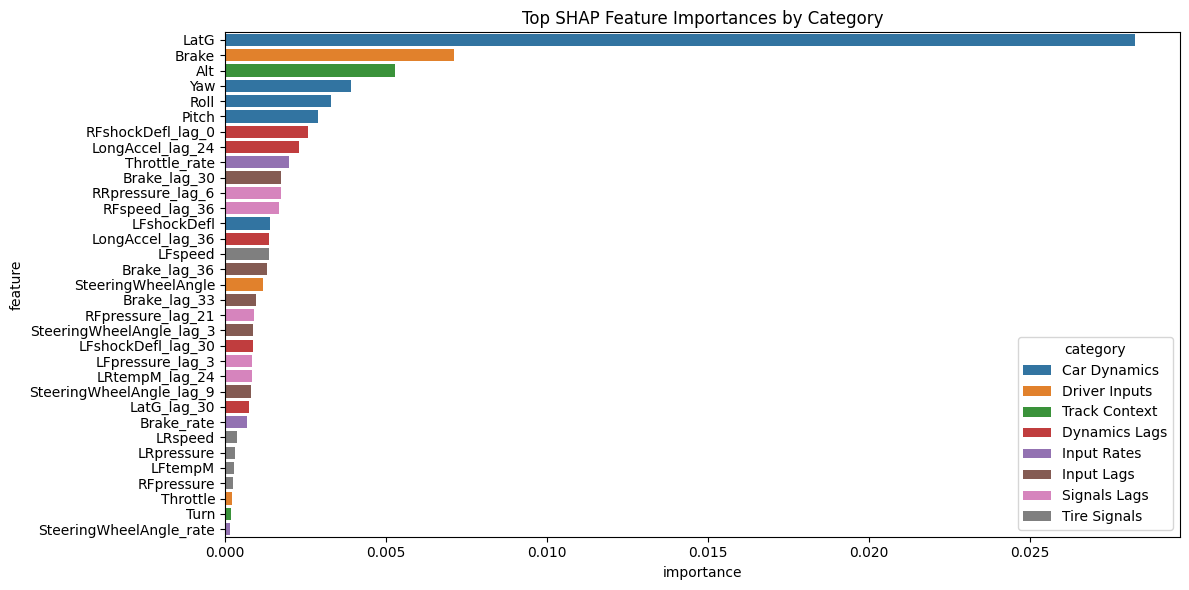

In [17]:
# --- SHAP Summary Barplot for Selected Features ---
def build_grouped_shap_df(X, shap_values, groups):
    mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
    shap_df = pd.DataFrame({"feature": X.columns, "importance": mean_abs_shap})
    def assign_category(feature):
        for cat, feat_list in groups.items():
            if feature in feat_list:
                return cat
        return "Other"
    shap_df["category"] = shap_df["feature"].apply(assign_category)
    return shap_df

shap_df = build_grouped_shap_df(X_train_val, shap_values[:, top_features], feature_groups)
plt.figure(figsize=(12, 6))
sns.barplot(data=shap_df.sort_values("importance", ascending=False), x="importance", y="feature", hue="category", dodge=False)
plt.title("Top SHAP Feature Importances by Category")
plt.tight_layout()
plt.show()

In [ ]:
best_model.get_booster().save_model("best_model.json")

In [ ]:
import joblib
joblib.dump(best_model, 'best_model.pkl')

['xgb_best_model.pkl']

In [ ]:
# import joblib
# top_feats = ['Pitch', 'SteeringWheelAngle_rate', 'LFspeed', 'Throttle_lag_15', 'RFpressure', 'LongAccel_lag_36', 'Roll', 'LongAccel_lag_33', 'RRpressure_lag_6', 'Turn', 'SteeringWheelAngle_lag_18', 'Alt', 'Yaw', 'RFshockDefl_lag_0', 'LatG', 'LFtempM', 'Throttle_rate', 'Brake_rate', 'LFpressure', 'RRspeed_lag_3', 'Brake', 'LatG_lag_3', 'SteeringWheelAngle', 'Brake_lag_30', 'RFspeed_lag_36', 'RFtempM_lag_27', 'SteeringWheelAngle_lag_9', 'LFtempM_lag_21', 'LFshockDefl', 'Throttle', 'Brake_lag_36', 'LRpressure', 'LongAccel_lag_24']
# best_model = joblib.load('xgb_best_model.pkl')
# y_pred_test = best_model.predict(X_test[top_feats])

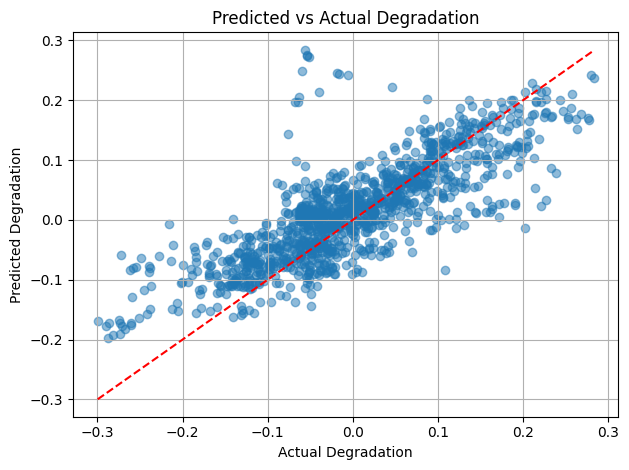

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_test, alpha=0.5)
plt.xlabel("Actual Degradation")
plt.ylabel("Predicted Degradation")
plt.title("Predicted vs Actual Degradation")
plt.grid(True)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")  # perfect line
plt.tight_layout()
plt.show()